Saving Balaji Fast Food Sales.csv to Balaji Fast Food Sales (1).csv
Before cleaning:
order_id                0
date                    0
item_name               0
item_type               0
item_price              0
quantity                0
transaction_amount      0
transaction_type      107
received_by             0
time_of_sale            0
dtype: int64

After cleaning:
order_id              0
date                  0
item_name             0
item_type             0
item_price            0
quantity              0
transaction_amount    0
transaction_type      0
received_by           0
time_of_sale          0
month                 0
dtype: int64
Dataset shape: (1000, 11)
Dataset Shape: (1000, 11)


,order_id,date,item_name,item_type,item_price,quantity,transaction_amount,transaction_type,received_by,time_of_sale,month
0,1,2022-03-07,Aalopuri,Fastfood,20,13,260,Unknown,Mr.,Night,3
1,2,2022-08-23,Vadapav,Fastfood,20,15,300,Cash,Mr.,Afternoon,8
2,3,2022-11-20,Vadapav,Fastfood,20,1,20,Cash,Mr.,Afternoon,11
3,4,2023-03-02,Sugarcane juice,Beverages,25,6,150,Online,Mr.,Night,3
4,5,2022-02-10,Sugarcane juice,Beverages,25,8,200,Online,Mr.,Evening,2



Number of usable rows: 1000

Linear Regression
R2 Score: 0.9035
MAE: 51.27
RMSE: 64.39

Decision Tree
R2 Score: 1.0
MAE: 0.0
RMSE: 0.0

Random Forest
R2 Score: 0.9999
MAE: 0.79
RMSE: 1.92


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

...

 Trainable params: 4,161 (16.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 0.8898 - mae: 0.7256 - val_loss: 0.6117 - val_mae: 0.5771
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.4994 - mae: 0.5321 - val_loss: 0.3253 - val_mae: 0.4219
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2627 - mae: 0.3854 - val_loss: 0.1717 - val_mae: 0.3153
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1240 - mae: 0.2659 - val_loss: 0.0928 - val_mae: 0.2314
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0643 - mae: 0.1973 - val_loss: 0.0622 - val_mae: 0.1907
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0436 - mae: 0.1627 - val_loss: 0.0441 - val_mae: 0.1657
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0302 - mae: 0.1341 - val_loss: 0.0360 - val_mae: 0.1505
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0231 - mae: 0.1190 - val_loss: 0.0296 - val_mae: 0.1362
Epoch 9/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.01

,Model,R2 Score,MAE,RMSE
0,Decision Tree,1.0000,0.0000,0.0000
1,Random Forest,0.9999,0.7872,1.9208
2,Neural Network,0.9897,15.9788,21.0882
3,Linear Regression,0.9035,51.2732,64.3875


Best model based on RMSE: Decision Tree


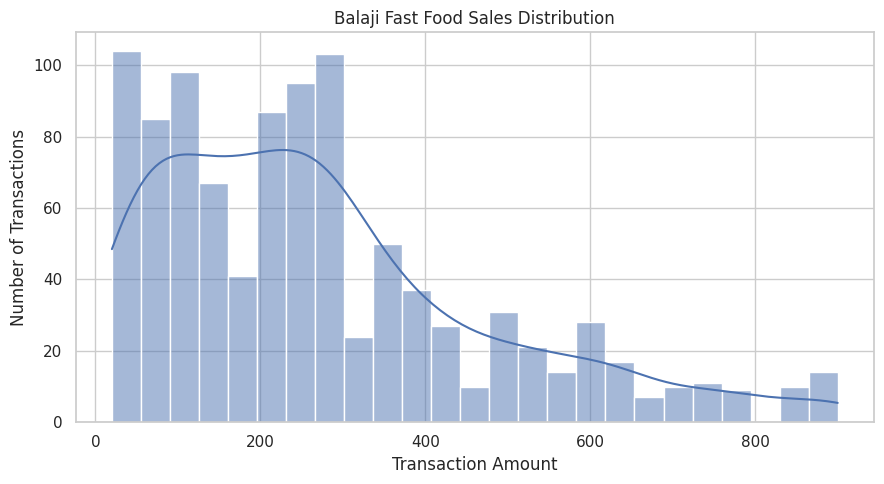

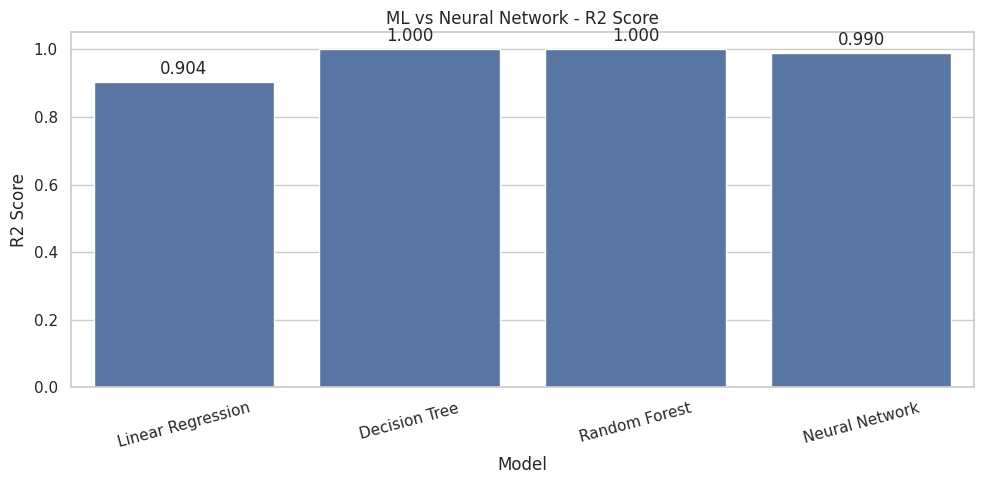

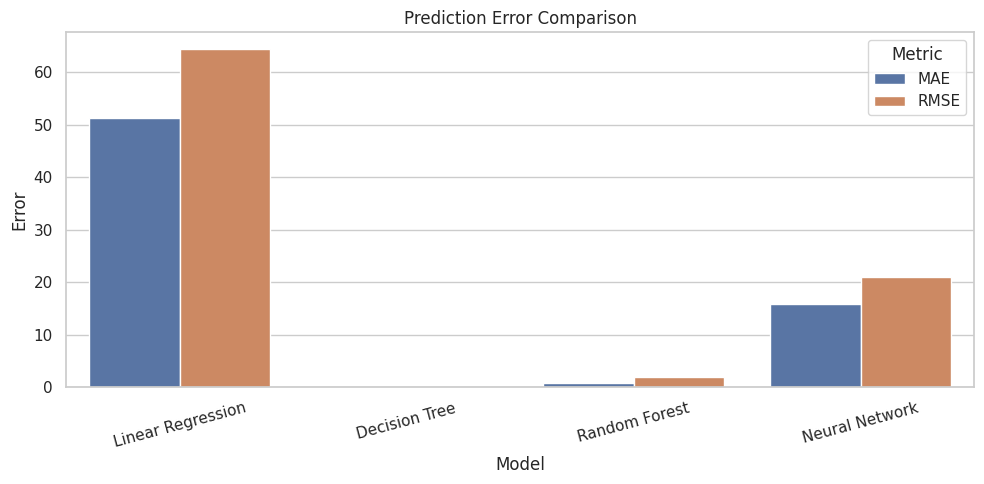

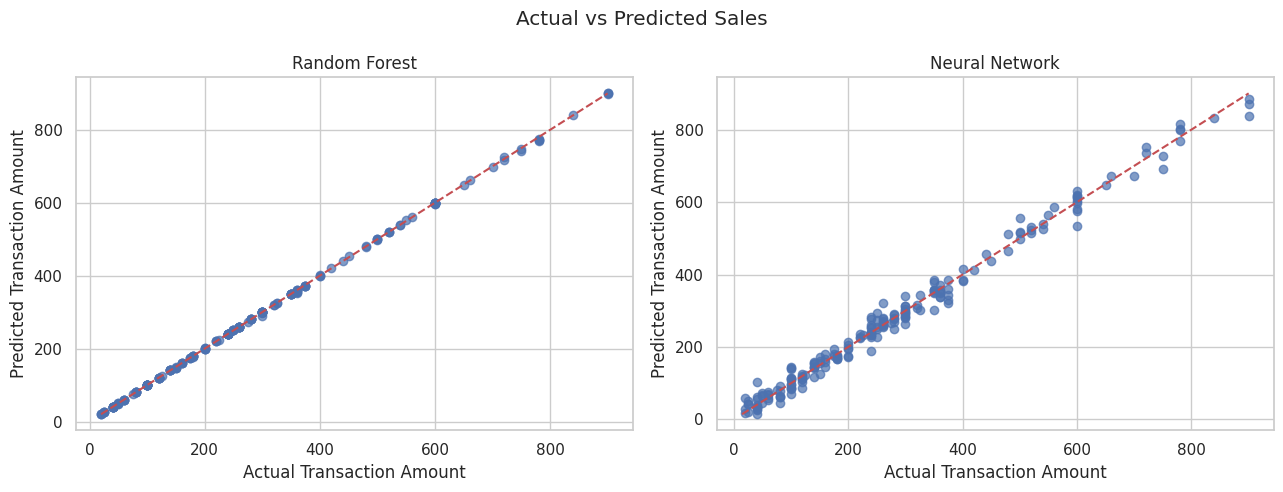

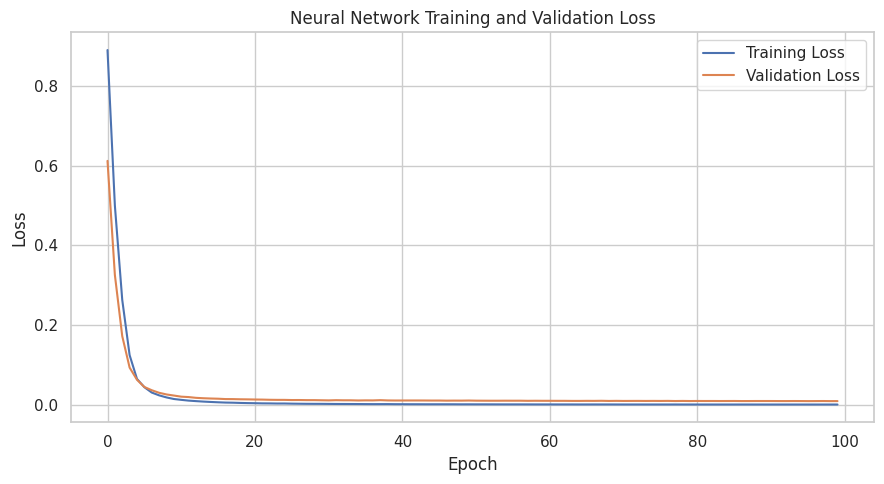

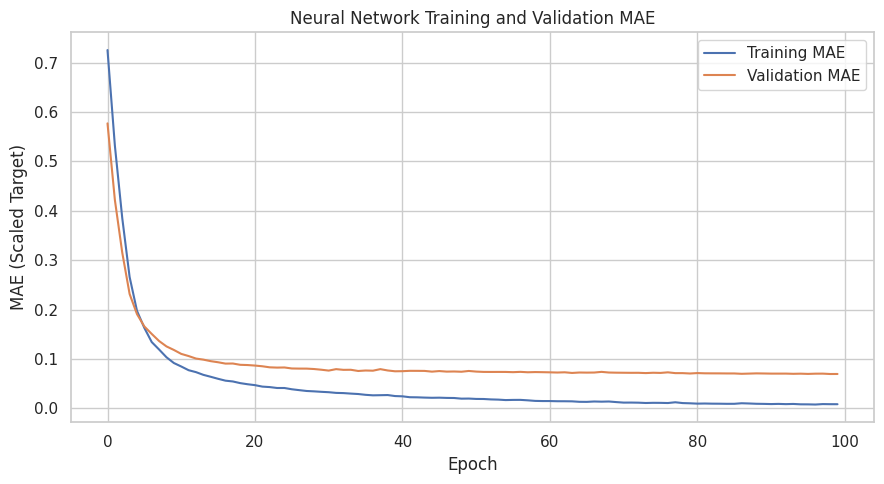

In [2]:

# MACHINE LEARNING + NEURAL NETWORK
# Dataset: Balaji Fast Food Sales

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

import keras
from keras.models import Sequential
from keras.layers import Dense, Flatten, Input
from keras.callbacks import EarlyStopping
sns.set_theme(style="whitegrid")

# STEP 1: Upload and load dataset
import pandas as pd
import numpy as np

from google.colab import files
uploaded = files.upload()
df = pd.read_csv("Balaji Fast Food Sales.csv")

# Check missing values
print("Before cleaning:")
print(df.isnull().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Fill missing categorical values
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].fillna("Unknown")

# Fill missing numerical values
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

# Convert date column
df["date"] = pd.to_datetime(
    df["date"], format="mixed", dayfirst=True
)

# Create month feature
df["month"] = df["date"].dt.month

print("\nAfter cleaning:")
print(df.isnull().sum())
print("Dataset shape:", df.shape)

print("Dataset Shape:", df.shape)
display(df.head())

# STEP 2: Prepare features
df["date"] = pd.to_datetime(
    df["date"], format="mixed",
    dayfirst=True, errors="coerce"
)

df["month"] = df["date"].dt.month
df["day_of_week"] = df["date"].dt.dayofweek

features = [
    "item_name", "item_type", "item_price", "quantity",
    "transaction_type", "received_by", "time_of_sale",
    "month", "day_of_week"
]

X = df[features].copy()
y = pd.to_numeric(df["transaction_amount"], errors="coerce")

# Keep rows with complete required values
valid = X.notna().all(axis=1) & y.notna()
X = X.loc[valid]
y = y.loc[valid]

# Convert categorical columns to numerical columns
X = pd.get_dummies(X, dtype=int)

print("\nNumber of usable rows:", len(X))

# STEP 3: Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scale features for Linear Regression and Neural Network
X_scaler = StandardScaler()
X_train_scaled = X_scaler.fit_transform(X_train)
X_test_scaled = X_scaler.transform(X_test)

y_scaler = StandardScaler()
y_train_scaled = y_scaler.fit_transform(
    np.asarray(y_train).reshape(-1, 1)
)

# STEP 4: Machine Learning models
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=10, random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        random_state=42
    )
}

results = []
predictions = {}

for name, model in models.items():

    if name == "Linear Regression":
        model.fit(X_train_scaled, y_train)
        pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        pred = model.predict(X_test)

    predictions[name] = pred

    r2 = r2_score(y_test, pred)
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))

    results.append({
        "Model": name,
        "R2 Score": r2,
        "MAE": mae,
        "RMSE": rmse
    })

    print(f"\n{name}")
    print("R2 Score:", round(r2, 4))
    print("MAE:", round(mae, 2))
    print("RMSE:", round(rmse, 2))

# STEP 5: Build Neural Network
nn_model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dense(1, activation="linear")
])

nn_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

nn_model.summary()

# STEP 6: Train Neural Network
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True
)

history = nn_model.fit(
    X_train_scaled,
    y_train_scaled,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

# STEP 7: Evaluate Neural Network
nn_pred_scaled = nn_model.predict(
    X_test_scaled, verbose=0
)

nn_pred = y_scaler.inverse_transform(
    nn_pred_scaled
).flatten()

predictions["Neural Network"] = nn_pred

nn_r2 = r2_score(y_test, nn_pred)
nn_mae = mean_absolute_error(y_test, nn_pred)
nn_rmse = np.sqrt(mean_squared_error(y_test, nn_pred))

print("\nNeural Network Results")
print("R2 Score:", round(nn_r2, 4))
print("MAE:", round(nn_mae, 2))
print("RMSE:", round(nn_rmse, 2))

results.append({
    "Model": "Neural Network",
    "R2 Score": nn_r2,
    "MAE": nn_mae,
    "RMSE": nn_rmse
})

# STEP 8: Compare all models
results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON")
display(
    results_df.sort_values(
        "RMSE"
    ).round(4).reset_index(drop=True)
)

best_model = results_df.loc[results_df["RMSE"].idxmin()]
print("Best model based on RMSE:", best_model["Model"])

# GRAPH 1: Sales distribution
plt.figure(figsize=(9, 5))
sns.histplot(y, bins=25, kde=True)
plt.title("Balaji Fast Food Sales Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

# GRAPH 2: R2 score comparison
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=results_df, x="Model", y="R2 Score")
plt.title("ML vs Neural Network - R2 Score")
plt.xticks(rotation=15)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)
plt.tight_layout()
plt.show()

# GRAPH 3: MAE and RMSE comparison
error_df = results_df.melt(
    id_vars="Model",
    value_vars=["MAE", "RMSE"],
    var_name="Metric",
    value_name="Error"
)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=error_df, x="Model",
    y="Error", hue="Metric"
)
plt.title("Prediction Error Comparison")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# GRAPH 4: Actual vs Predicted
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, name in zip(
    axes, ["Random Forest", "Neural Network"]
):
    pred = predictions[name]
    ax.scatter(y_test, pred, alpha=0.7)

    low = min(float(y_test.min()), float(np.min(pred)))
    high = max(float(y_test.max()), float(np.max(pred)))

    ax.plot([low, high], [low, high], "r--")
    ax.set_title(name)
    ax.set_xlabel("Actual Transaction Amount")
    ax.set_ylabel("Predicted Transaction Amount")

fig.suptitle("Actual vs Predicted Sales")
plt.tight_layout()
plt.show()

# GRAPH 5: Neural Network loss
plt.figure(figsize=(9, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Neural Network Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

# GRAPH 6: Neural Network MAE
plt.figure(figsize=(9, 5))
plt.plot(history.history["mae"], label="Training MAE")
plt.plot(history.history["val_mae"], label="Validation MAE")
plt.title("Neural Network Training and Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE (Scaled Target)")
plt.legend()
plt.tight_layout()
plt.show()